# Bloque C - C1: Análisis de la tinción Giemsa y espacios de color

**Objetivo:** estudiar cómo se ven los colores de la tinción Giemsa y comparar los espacios **RGB, HSV y Lab** para encontrar qué canales y rangos separan mejor:

- **Fondo** (plasma, zona clara entre células)
- **Eritrocitos no parasitados** (Uninfected)
- **Eritrocitos parasitados** (Parasitized)
- **Glóbulos blancos** (White_Blood_Cell, WBC)

**La tinción Giemsa en pocas palabras:** es una mezcla de **eosina** (colorante ácido, rosado) y **azul de metileno / azures** (colorantes básicos, azul-violeta).
- La eosina se une a la hemoglobina → los eritrocitos se ven **rosa pálido**.
- Los azures se unen al ADN/ARN → la **cromatina del parásito** y el **núcleo de los glóbulos blancos** se ven **violeta oscuro**.
- El fondo casi no toma colorante → se ve **claro**.

Entonces esperamos que lo que distingue a un parásito sea "un punto **oscuro** y **violeta** dentro de un eritrocito rosado".

**Regla del proyecto:** todo el análisis se hace **solo con train**. Test queda para la evaluación final.

In [33]:
# BLOQUE C - C1: Análisis de tinción y espacios de color
# Objetivo: estudiar los colores de las imágenes teñidas con Giemsa
# para identificar qué canales permiten resaltar mejor los parásitos.

import sys
sys.path.append("..")  # el notebook está en color_stain/, subimos un nivel para poder importar common/

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve, adjusted_rand_score
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture

from common.config import SEED, LABEL_PARASITIZED, LABEL_UNINFECTED, LABEL_WBC
from common.io_utils import cargar_subset, cargar_imagen, cargar_gt
from common.generar_gt_utils import celulas_desde_gt
from segmentation.preprocess import mascara_circular

# Generador de números aleatorios con semilla fija, para que los resultados se puedan repetir
rng = np.random.default_rng(SEED)

# Nombres de las 4 clases que vamos a comparar
FONDO = "Fondo"
CLASES = [FONDO, LABEL_UNINFECTED, LABEL_PARASITIZED, LABEL_WBC]

# Un color fijo para cada clase en todos los gráficos
COLOR_CLASE = {
    FONDO: "#2a78d6",
    LABEL_UNINFECTED: "#eb6834",
    LABEL_PARASITIZED: "#1baf7a",
    LABEL_WBC: "#eda100",
}

# Nombres de los 9 canales: 3 de cada espacio de color
CANALES = ["R", "G", "B", "H", "S", "V", "L", "a", "b"]

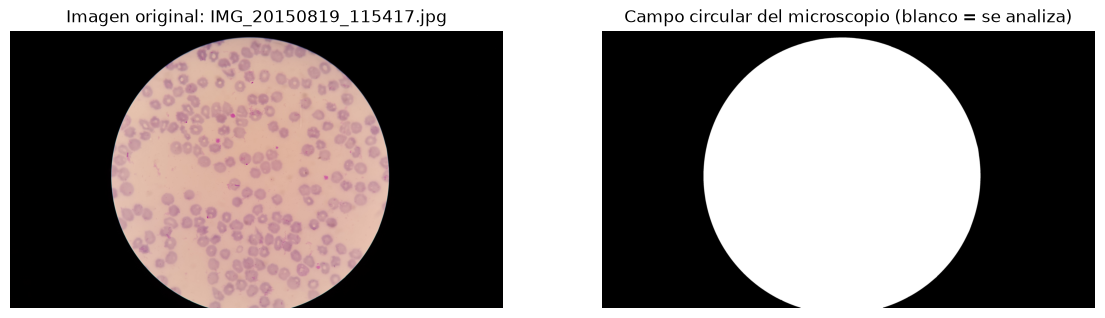

Paciente: 208C67P28N_ThinF
Imagen: IMG_20150819_115417.jpg
Dimensiones: (2988, 5312, 3)


In [34]:
# Seleccionamos la primera imagen del conjunto de entrenamiento
imagen_info = cargar_subset("train")[0]

patient_id = imagen_info["patient_id"]
image_id = imagen_info["image_id"]

# Cargamos la imagen original en RGB
imagen_rgb = cargar_imagen(patient_id, image_id)

# Obtenemos la máscara del campo circular del microscopio
campo = mascara_circular(imagen_rgb)

# Mostramos la imagen y la máscara del campo
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].imshow(imagen_rgb)
ax[0].set_title(f"Imagen original: {image_id}")
ax[1].imshow(campo, cmap="gray")
ax[1].set_title("Campo circular del microscopio (blanco = se analiza)")
for a in ax:
    a.axis("off")
plt.show()

print("Paciente:", patient_id)
print("Imagen:", image_id)
print("Dimensiones:", imagen_rgb.shape)

## 1. Los tres espacios de color

| Espacio | Canales | Qué mide | Rango en OpenCV (uint8) |
|---|---|---|---|
| **RGB** | R, G, B | cantidad de rojo, verde y azul | 0-255 |
| **HSV** | H (tono), S (saturación), V (brillo) | separa el *color* del *brillo* | H: 0-179 (son grados/2), S y V: 0-255 |
| **Lab** | L (luminosidad), a (verde ↔ rojo/magenta), b (azul ↔ amarillo) | pensado para parecerse a la percepción humana | L: 0-255 (= L·255/100), a y b: 0-255 (128 = neutro) |

**Ojo con dos detalles de OpenCV**, importantes para pasarle los rangos al Bloque A:
- En Lab, `a` y `b` están corridos +128: **a > 128** es tirando a rojo/magenta, **b < 128** es tirando a azul. Lo violeta tiene a alto y b bajo.
- **H es circular:** el rojo/rosa está a la vez cerca de 0 y cerca de 179. Por eso la mediana o un umbral sobre H "crudo" engañan. Para analizarlo usamos un **H rotado**: `H_rot = (H + 90) % 180`, que lleva el rojo al centro (≈90) y deja el violeta/azul más abajo (≈60-80).

La siguiente función calcula los 9 canales de una vez.

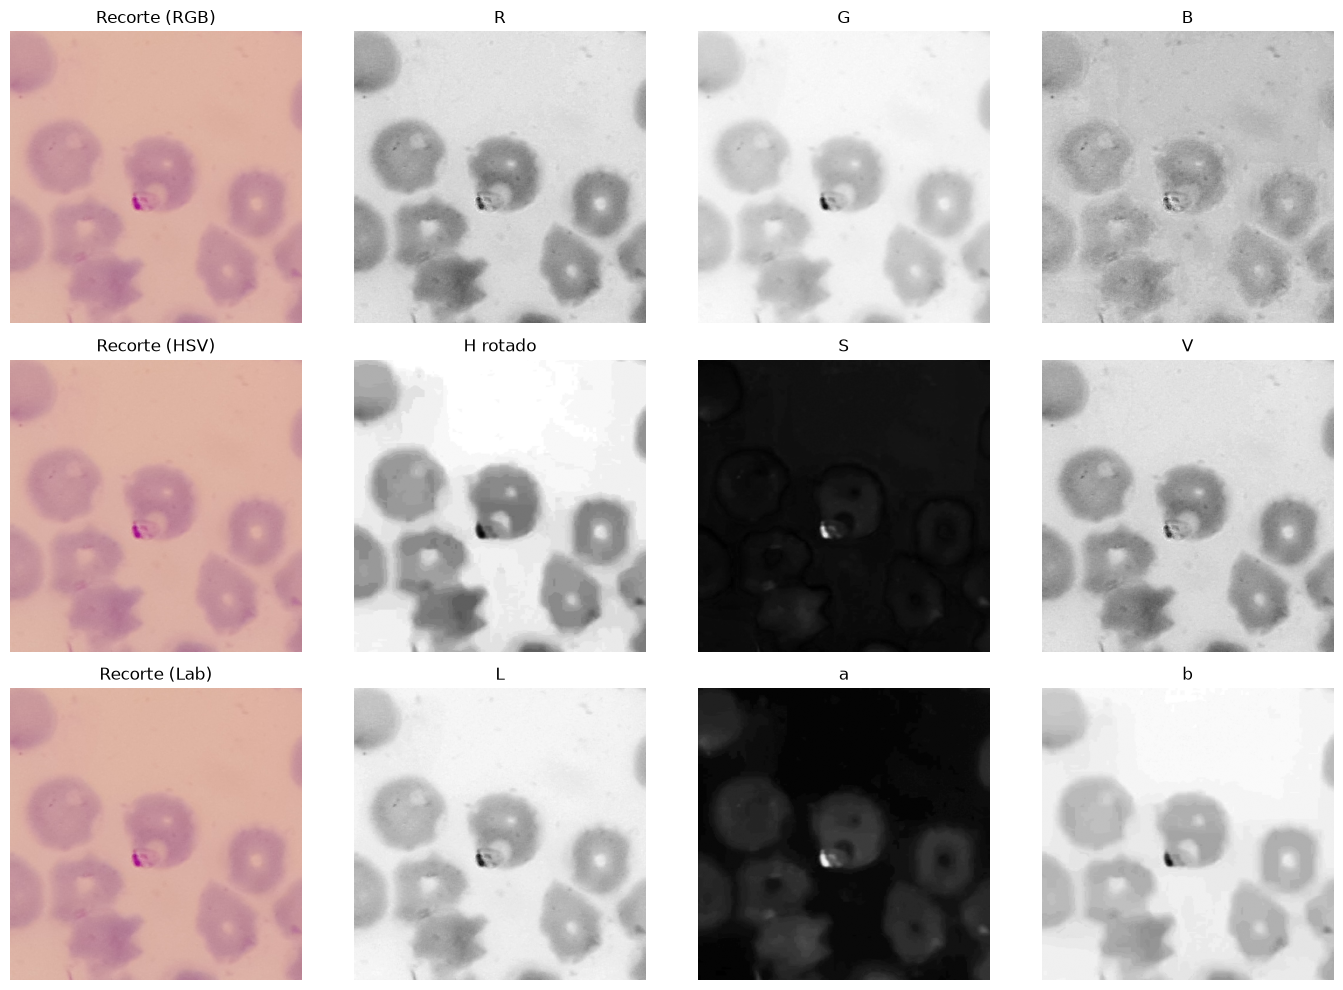

In [35]:
def calcular_canales(imagen_rgb):
    # Devuelve una matriz (alto, ancho, 9) con los canales R, G, B, H, S, V, L, a, b
    hsv = cv2.cvtColor(imagen_rgb, cv2.COLOR_RGB2HSV)
    lab = cv2.cvtColor(imagen_rgb, cv2.COLOR_RGB2LAB)
    return np.dstack([imagen_rgb, hsv, lab])


def rotar_tono(h):
    # Rota el tono 90 posiciones (180 grados) para que el rojo quede en el centro y no partido entre 0 y 179
    return (h.astype(np.int32) + 90) % 180


# Para ver bien los detalles hacemos zoom sobre una zona con una célula parasitada
anotaciones, _ = cargar_gt(patient_id, image_id)
parasitada = next(a for a in anotaciones if a["label"] == LABEL_PARASITIZED)
cx, cy = parasitada["polygon"].mean(axis=0).astype(int)  # centro de la célula
mitad = 250
zoom = imagen_rgb[cy - mitad:cy + mitad, cx - mitad:cx + mitad]

canales_zoom = calcular_canales(zoom)

# Mostramos el recorte y sus 9 canales (una fila por espacio de color)
fig, ax = plt.subplots(3, 4, figsize=(14, 10))
for fila, espacio in enumerate(["RGB", "HSV", "Lab"]):
    ax[fila, 0].imshow(zoom)
    ax[fila, 0].set_title(f"Recorte ({espacio})")
    for col in range(3):
        k = 3 * fila + col
        canal = canales_zoom[:, :, k]
        if CANALES[k] == "H":
            canal = rotar_tono(canal)
            nombre = "H rotado"
        else:
            nombre = CANALES[k]
        ax[fila, col + 1].imshow(canal, cmap="gray")
        ax[fila, col + 1].set_title(nombre)
for a in ax.ravel():
    a.axis("off")
plt.tight_layout()
plt.show()

**Qué mirar:** en G, L y b el parásito y el núcleo de los glóbulos blancos aparecen como manchas **oscuras**; en a y S aparecen **claros**. El fondo se distingue mejor de las células en G y L. En R y V casi no hay contraste (los eritrocitos y el fondo reflejan mucho rojo).

## 2. Base de píxeles etiquetados (solo train)

Para comparar los canales de forma objetiva armamos una tabla de píxeles con su clase:
1. Para cada imagen de train se construye un **mapa de clases** a partir de los polígonos del GT.
2. **Fondo** = píxeles dentro del campo circular que no caen en ningún polígono.
3. De cada clase y cada imagen tomamos al azar hasta `N_POR_CLASE` píxeles (las imágenes tienen ~16 millones de píxeles, no hace falta usarlos todos).

In [36]:
N_POR_CLASE = 5000  # píxeles por clase y por imagen
CODIGO = {FONDO: 0, LABEL_UNINFECTED: 1, LABEL_PARASITIZED: 2, LABEL_WBC: 3}

tablas = []
for reg in cargar_subset("train"):
    img = cargar_imagen(reg["patient_id"], reg["image_id"])
    anot, _ = cargar_gt(reg["patient_id"], reg["image_id"])
    campo_img = mascara_circular(img)

    # Mapa de clases: -1 = fuera del campo, 0 = fondo, y luego cada polígono pinta su clase
    mapa = np.full(img.shape[:2], -1, dtype=np.int8)
    mapa[campo_img] = 0
    for clase in [LABEL_UNINFECTED, LABEL_PARASITIZED, LABEL_WBC]:
        for a in anot:
            if a["label"] == clase and a["polygon"] is not None:
                puntos = np.round(a["polygon"]).astype(np.int32)
                cv2.fillPoly(mapa, [puntos], CODIGO[clase])

    canales_img = calcular_canales(img)

    # Muestreo aleatorio de píxeles de cada clase
    for clase, codigo in CODIGO.items():
        filas_px, cols_px = np.nonzero(mapa == codigo)
        if len(filas_px) == 0:
            continue  # por ejemplo, imágenes sin glóbulos blancos
        elegidos = rng.choice(len(filas_px), size=min(N_POR_CLASE, len(filas_px)), replace=False)
        valores = canales_img[filas_px[elegidos], cols_px[elegidos]]

        t = pd.DataFrame(valores.astype(float), columns=CANALES)  # float para evitar desbordes de uint8
        t["clase"] = clase
        t["image_id"] = reg["image_id"]
        tablas.append(t)

pixeles = pd.concat(tablas, ignore_index=True)
pixeles["H_rot"] = rotar_tono(pixeles["H"])

print("Píxeles por clase:")
print(pixeles["clase"].value_counts())

Píxeles por clase:
clase
Fondo               60000
Uninfected          60000
Parasitized         60000
White_Blood_Cell    25000
Name: count, dtype: int64


### Mediana de cada canal por clase
Un primer resumen numérico. Fijate que la mediana de **H crudo** salta de ~6 a ~170 entre clases que en realidad son parecidas: es el problema de que H sea circular. Con **H_rot** se ve el orden real.

In [37]:
CANALES_ANALISIS = ["R", "G", "B", "H_rot", "S", "V", "L", "a", "b"]  # usamos H rotado en vez de H crudo

medianas = pixeles.groupby("clase")[CANALES + ["H_rot"]].median().loc[CLASES]
medianas

,R,G,B,H,S,V,L,a,b,H_rot
clase,,,,,,,,,,
Fondo,220.0,182.0,167.0,9.0,61.0,220.0,196.0,140.0,141.0,98.0
Uninfected,204.0,155.0,156.0,6.0,64.0,204.0,175.0,146.0,136.0,91.0
Parasitized,203.0,149.0,152.0,170.0,70.0,203.0,171.0,148.0,134.0,89.0
White_Blood_Cell,163.0,52.0,134.0,157.0,171.0,163.0,105.0,167.0,108.0,68.0


## 3. Histogramas por canal y por clase

Cada gráfico muestra la distribución de un canal para las 4 clases (normalizada, para que la clase con más píxeles no tape a las otras). **Un canal es bueno para separar dos clases si sus histogramas se superponen poco.**

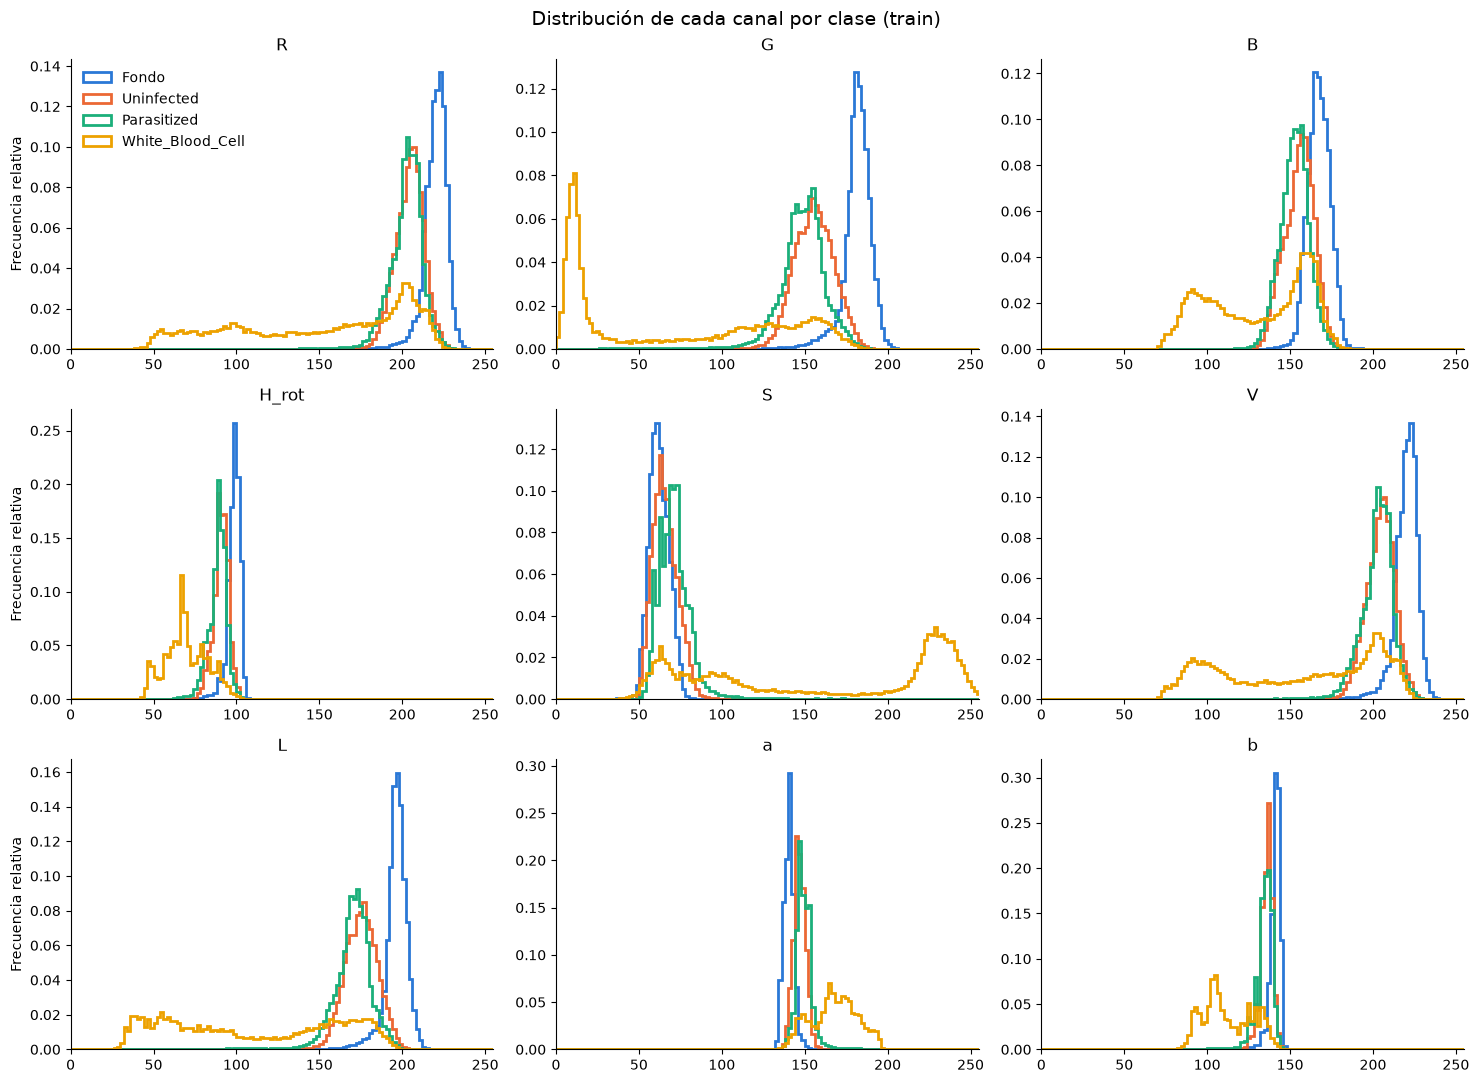

In [38]:
fig, ax = plt.subplots(3, 3, figsize=(15, 11))
bins = np.arange(0, 257, 2)

for k, canal in enumerate(CANALES_ANALISIS):
    eje = ax.ravel()[k]
    for clase in CLASES:
        valores = pixeles.loc[pixeles["clase"] == clase, canal]
        pesos = np.ones(len(valores)) / len(valores)  # frecuencia relativa: cada clase suma 1
        eje.hist(valores, bins=bins, weights=pesos, histtype="step", linewidth=2,
                 color=COLOR_CLASE[clase], label=clase)
    eje.set_title(canal)
    eje.set_xlim(0, 255)
    eje.spines[["top", "right"]].set_visible(False)

for eje in ax[:, 0]:
    eje.set_ylabel("Frecuencia relativa")
ax[0, 0].legend(loc="upper left", frameon=False)
fig.suptitle("Distribución de cada canal por clase (train)", fontsize=14)
plt.tight_layout()
plt.show()

**Qué se ve:**
- **Fondo vs células:** el fondo está claramente más a la derecha (más claro) en **G** y **L**.
- **Glóbulos blancos:** tienen una cola muy oscura en G y L, y se van hacia valores **bajos de b** (azul-violeta) y **altos de a y S**.
- **Parasitadas vs no parasitadas:** los histogramas casi se superponen. Tiene sentido: el parásito ocupa una parte chica de la célula y el resto es citoplasma rosado igual al de una célula sana. Por eso más abajo analizamos **por célula** y no solo por píxel.

## 4. Separabilidad de cada canal (AUC)

Para no decidir "a ojo", medimos con el **AUC** (área bajo la curva ROC) qué tan bien un canal solo separa dos grupos de píxeles:
- **AUC = 0.5** → el canal no separa nada (como tirar una moneda).
- **AUC = 1** → separa perfecto.

Como un canal puede separar porque una clase tiene valores más *altos* o más *bajos*, tomamos `max(AUC, 1 − AUC)`.

Comparamos tres problemas, que son justamente los que necesita el Bloque A:
1. **Fondo vs células** (para segmentar).
2. **Glóbulos blancos vs eritrocitos** (para excluir WBC).
3. **Parasitados vs no parasitados** (a nivel píxel).

> **Ojo con el problema 3:** el GT marca la célula entera, no el parásito. Por eso **todos** los píxeles de una célula parasitada quedan etiquetados como "Parasitized", aunque la mayoría sean citoplasma normal, igual al de una célula sana. Este AUC mide la separación entre **píxeles de células de distinta clase**, no entre píxeles de parásito y píxeles sanos. Es esperable que dé bajo, y no significa que el color del parásito no se distinga.

In [39]:
def auc_simetrico(es_positivo, valores):
    # AUC sin importar si la clase positiva tiene valores más altos o más bajos
    auc = roc_auc_score(es_positivo, valores)
    return max(auc, 1 - auc)


celulas_px = pixeles[pixeles["clase"] != FONDO]
eritrocitos_px = pixeles[pixeles["clase"].isin([LABEL_PARASITIZED, LABEL_UNINFECTED])]

problemas = {
    "Fondo vs células": (pixeles["clase"] != FONDO, pixeles),
    "WBC vs eritrocitos": (celulas_px["clase"] == LABEL_WBC, celulas_px),
    "Parasitado vs no parasitado (píxel)": (eritrocitos_px["clase"] == LABEL_PARASITIZED, eritrocitos_px),
}

auc_pixel = pd.DataFrame({
    nombre: {canal: auc_simetrico(y, datos[canal]) for canal in CANALES_ANALISIS}
    for nombre, (y, datos) in problemas.items()
}).round(3)

auc_pixel

,Fondo vs células,WBC vs eritrocitos,Parasitado vs no parasitado (píxel)
R,0.939,0.821,0.558
G,0.969,0.866,0.649
B,0.890,0.704,0.598
H_rot,0.935,0.917,0.614
S,0.748,0.857,0.675
V,0.939,0.821,0.558
L,0.967,0.858,0.632
a,0.942,0.886,0.677
b,0.910,0.923,0.571


**Lectura de la tabla:**
- **Fondo vs células:** el mejor es **G** (≈0.97), casi igual a **L**. Esto confirma que el Bloque A hace bien en usar Otsu sobre el canal verde.
- **WBC vs eritrocitos:** el mejor es **b** de Lab (≈0.92), seguido de H_rot y a. Es el canal que mejor captura lo "violeta".
- **Parasitado vs no parasitado (píxel):** todos dan bajo (≤0.68). Como explicamos arriba, la mayoría de los píxeles "Parasitized" son citoplasma normal, así que este número subestima cuánto se distingue el parásito. Para medirlo mejor hay que mirar **los píxeles más oscuros de cada célula**.

## 5. Análisis por célula: los píxeles más extremos de cada eritrocito

Idea: una célula parasitada tiene *algunos* píxeles muy oscuros/violetas (el parásito). Entonces, en vez de mirar todos los píxeles, para cada célula calculamos:
- el **percentil 5** de cada canal (representa los píxeles más bajos/oscuros de la célula), y
- el **percentil 95** (los más altos, útil para a y S, donde lo violeta da valores altos).

Usamos `celulas_desde_gt("train")`, que devuelve el recorte y la máscara de cada célula del GT.

In [40]:
filas_celulas = []
for meta, recorte, mascara in celulas_desde_gt("train"):
    valores = calcular_canales(recorte)[mascara > 0].astype(float)  # solo los píxeles dentro de la célula
    fila = {"cell_id": meta["cell_id"], "label": meta["label"]}
    for k, canal in enumerate(CANALES):
        columna = valores[:, k] if canal != "H" else rotar_tono(valores[:, k])
        nombre = canal if canal != "H" else "H_rot"
        fila[f"{nombre}_p5"] = np.percentile(columna, 5)
        fila[f"{nombre}_p95"] = np.percentile(columna, 95)
    filas_celulas.append(fila)

celulas = pd.DataFrame(filas_celulas)
print("Células por clase (train):")
print(celulas["label"].value_counts())

# AUC de cada estadístico para separar parasitadas de no parasitadas
eritrocitos = celulas[celulas["label"] != LABEL_WBC]
y_par = eritrocitos["label"] == LABEL_PARASITIZED

columnas_stats = [c for c in celulas.columns if c.endswith("_p5") or c.endswith("_p95")]
auc_celula = pd.Series({c: auc_simetrico(y_par, eritrocitos[c]) for c in columnas_stats})
auc_celula.sort_values(ascending=False).round(3).head(8)

Células por clase (train):
label
Uninfected          2135
Parasitized          217
White_Blood_Cell      10
Name: count, dtype: int64


G_p5        0.874
L_p5        0.864
H_rot_p5    0.857
b_p5        0.854
a_p95       0.847
S_p95       0.841
V_p5        0.812
R_p5        0.812
dtype: float64

**Resultado:** a nivel célula la separación mejora mucho (AUC ≈0.87 contra ≈0.68 por píxel). Los mejores estadísticos son **G_p5**, **L_p5** y **b_p5** (el parásito es oscuro y violeta), seguidos de **a_p95** y **S_p95**.

Ojo con el desbalance: hay ~10 veces más células sanas que parasitadas. El AUC no se ve afectado por eso, pero hay que tenerlo en cuenta en C5.

Comparamos las distribuciones de los dos mejores estadísticos:

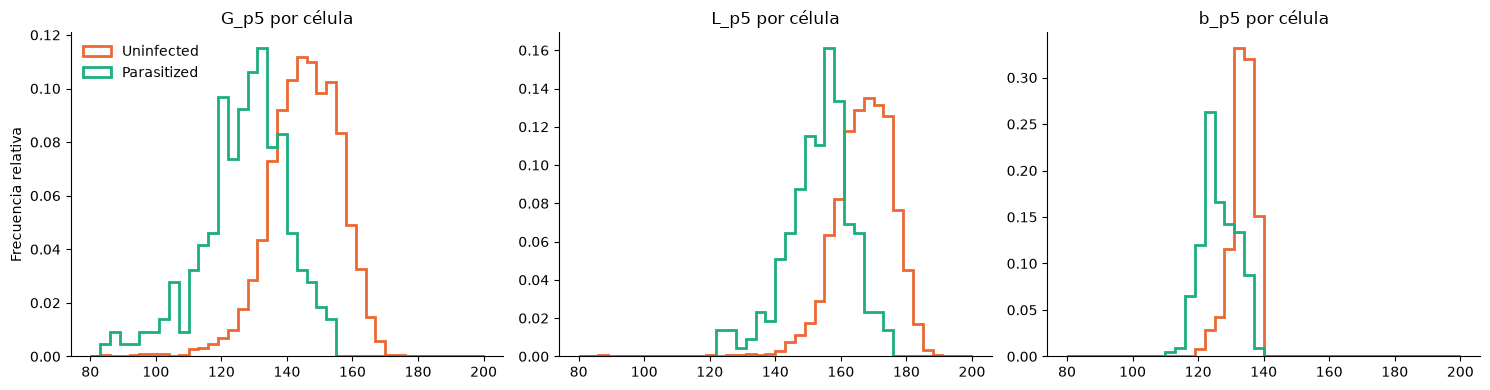

In [41]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for eje, col in zip(ax, ["G_p5", "L_p5", "b_p5"]):
    for clase in [LABEL_UNINFECTED, LABEL_PARASITIZED]:
        valores = eritrocitos.loc[eritrocitos["label"] == clase, col]
        pesos = np.ones(len(valores)) / len(valores)  # frecuencia relativa: cada clase suma 1
        eje.hist(valores, bins=40, range=(80, 200), weights=pesos, histtype="step",
                 linewidth=2, color=COLOR_CLASE[clase], label=clase)
    eje.set_title(f"{col} por célula")
    eje.spines[["top", "right"]].set_visible(False)
ax[0].set_ylabel("Frecuencia relativa")
ax[0].legend(loc="upper left", frameon=False)
plt.tight_layout()
plt.show()

## 6. Rangos y umbrales sugeridos (índice de Youden, solo train)

Para pasarle **valores concretos** al Bloque A buscamos, para el mejor canal de cada problema, el umbral que maximiza el **índice de Youden** = sensibilidad + especificidad − 1 (el punto de la curva ROC más alejado de la diagonal). Es una forma simple y estándar de elegir un umbral.

La función también decide el **sentido** del umbral (`<` o `>`) comparando las medianas de las dos clases.

> Estos umbrales son **exploratorios**. Los umbrales definitivos para clasificar se ajustan en C5.

In [42]:
def umbral_youden(es_positivo, valores):
    # Devuelve el sentido ('<' o '>'), el umbral, la sensibilidad y la especificidad
    valores = np.asarray(valores, dtype=float)
    es_positivo = np.asarray(es_positivo)

    # Si la clase positiva tiene valores más bajos, el umbral es del tipo "valor < t"
    sentido = "<" if np.median(valores[es_positivo]) < np.median(valores[~es_positivo]) else ">"
    puntaje = -valores if sentido == "<" else valores  # roc_curve supone "más alto = positivo"

    fpr, tpr, umbrales = roc_curve(es_positivo, puntaje)
    k = np.argmax(tpr - fpr)  # índice de Youden
    umbral = -umbrales[k] if sentido == "<" else umbrales[k]
    return sentido, umbral, tpr[k], 1 - fpr[k]


# (problema, canal, clase positiva, datos)
casos = [
    ("Células (vs fondo)", "G", pixeles["clase"] != FONDO, pixeles),
    ("Células (vs fondo)", "L", pixeles["clase"] != FONDO, pixeles),
    ("WBC (vs eritrocitos)", "b", celulas_px["clase"] == LABEL_WBC, celulas_px),
    ("WBC (vs eritrocitos)", "H_rot", celulas_px["clase"] == LABEL_WBC, celulas_px),
    ("WBC (vs eritrocitos)", "a", celulas_px["clase"] == LABEL_WBC, celulas_px),
    ("Parasitada, por célula", "G_p5", y_par, eritrocitos),
    ("Parasitada, por célula", "L_p5", y_par, eritrocitos),
    ("Parasitada, por célula", "b_p5", y_par, eritrocitos),
]

filas = []
for problema, canal, y, datos in casos:
    sentido, umbral, sens, espec = umbral_youden(y, datos[canal])
    filas.append({
        "problema": problema,
        "canal": canal,
        "regla": f"{canal} {sentido} {umbral:.0f}",
        "sensibilidad": round(sens, 3),
        "especificidad": round(espec, 3),
        "AUC": round(auc_simetrico(y, datos[canal]), 3),
    })

umbrales_c1 = pd.DataFrame(filas)
umbrales_c1

,problema,canal,regla,sensibilidad,especificidad,AUC
0,Células (vs fondo),G,G < 170,0.939,0.913,0.969
1,Células (vs fondo),L,L < 187,0.939,0.909,0.967
2,WBC (vs eritrocitos),b,b < 127,0.799,0.935,0.923
3,WBC (vs eritrocitos),H_rot,H_rot < 80,0.795,0.937,0.917
4,WBC (vs eritrocitos),a,a > 155,0.785,0.949,0.886
5,"Parasitada, por célula",G_p5,G_p5 < 134,0.751,0.859,0.874
6,"Parasitada, por célula",L_p5,L_p5 < 159,0.788,0.810,0.864
7,"Parasitada, por célula",b_p5,b_p5 < 129,0.760,0.829,0.854


### Rangos por clase (percentiles 5-95)
Además del umbral, le pasamos al Bloque A el rango "típico" (90 % central) de cada clase en los canales que resultaron útiles.

In [43]:
def rango_5_95(x):
    return f"{np.percentile(x, 5):.0f} - {np.percentile(x, 95):.0f}"

rangos = pixeles.groupby("clase")[["G", "L", "a", "b", "H_rot", "S"]].agg(rango_5_95).loc[CLASES]
rangos

,G,L,a,b,H_rot,S
clase,,,,,,
Fondo,164 - 193,182 - 205,135 - 145,135 - 144,91 - 103,52 - 72
Uninfected,136 - 175,159 - 191,140 - 152,129 - 140,82 - 97,54 - 78
Parasitized,124 - 169,151 - 187,142 - 157,124 - 140,78 - 95,58 - 88
White_Blood_Cell,5 - 164,38 - 183,144 - 190,91 - 135,48 - 91,57 - 243


**¿Es estable la tinción entre imágenes?** Si el color del fondo cambiara mucho de una imagen a otra, un umbral global no serviría y habría que normalizar primero (C2). Miramos la mediana del fondo por imagen:

In [44]:
fondo_por_imagen = pixeles[pixeles["clase"] == FONDO].groupby("image_id")[["G", "L", "a", "b"]].median()
print(fondo_por_imagen)
print("\nDiferencia máxima entre imágenes:")
print(fondo_por_imagen.max() - fondo_por_imagen.min())

                             G      L      a      b
image_id                                           
IMG_20150813_130332.jpg  184.0  197.0  137.0  144.0
IMG_20150813_131330.jpg  184.0  196.0  136.0  143.0
IMG_20150813_162016.jpg  181.0  197.0  142.0  139.0
IMG_20150813_163120.jpg  179.0  195.0  141.0  139.0
IMG_20150819_115417.jpg  180.0  196.0  141.0  141.0
IMG_20150819_121456.jpg  182.0  197.0  140.0  141.0
IMG_20150819_133350.jpg  183.0  198.0  141.0  141.0
IMG_20150819_133447.jpg  180.0  196.0  141.0  139.0
IMG_20150930_161825.jpg  177.0  193.0  141.0  143.0
IMG_20150930_162315.jpg  181.0  196.0  141.0  141.0
IMG_20151005_121554.jpg  180.0  193.0  137.0  140.0
IMG_20151005_121656.jpg  185.0  198.0  136.0  141.0

Diferencia máxima entre imágenes:
G    8.0
L    5.0
a    6.0
b    5.0
dtype: float64


La variación del fondo entre imágenes de train es chica (menos de ~10 niveles en cada canal), así que los umbrales globales son razonables. Igual la normalización de C2 puede ayudar con las imágenes de test (otros pacientes).

## 7. Agrupamiento exploratorio: K-means y GMM

Ahora probamos lo contrario: **sin usar las etiquetas**, ¿se forman solos grupos de color que coincidan con las clases? Para cada espacio de color:
1. Tomamos una muestra de píxeles de train.
2. **Estandarizamos** los 3 canales (media 0, desvío 1) para que ninguno pese más por su escala.
3. Agrupamos en 4 grupos (uno por clase esperada) con **K-means** (grupos "redondos", asigna cada píxel al centro más cercano) y con **GMM** (mezcla de gaussianas, permite grupos alargados y de distinto tamaño).
4. Comparamos los grupos con las clases reales usando el **ARI** (Adjusted Rand Index): 0 = coincidencia al azar, 1 = coincidencia perfecta.

En HSV usamos H rotado, por el problema de que H es circular.

In [45]:
muestra = pixeles.sample(20000, random_state=SEED)
ESPACIOS = {"RGB": ["R", "G", "B"], "HSV": ["H_rot", "S", "V"], "Lab": ["L", "a", "b"]}

resultados_cluster = []
grupos_kmeans = {}
for espacio, cols in ESPACIOS.items():
    X = muestra[cols].values
    X = (X - X.mean(axis=0)) / X.std(axis=0)  # estandarización

    kmeans = KMeans(n_clusters=4, random_state=SEED, n_init=10).fit(X)
    gmm = GaussianMixture(n_components=4, random_state=SEED).fit(X)

    grupos_kmeans[espacio] = kmeans.labels_
    resultados_cluster.append({
        "espacio": espacio,
        "ARI K-means": round(adjusted_rand_score(muestra["clase"], kmeans.labels_), 3),
        "ARI GMM": round(adjusted_rand_score(muestra["clase"], gmm.predict(X)), 3),
    })

pd.DataFrame(resultados_cluster)

,espacio,ARI K-means,ARI GMM
0,RGB,0.315,0.408
1,HSV,0.375,0.391
2,Lab,0.383,0.412


Para entender mejor qué agrupó, miramos la **tabla de contingencia** (clase real vs grupo) de K-means en Lab:

In [46]:
pd.crosstab(muestra["clase"], grupos_kmeans["Lab"], rownames=["clase real"], colnames=["grupo K-means (Lab)"]).loc[CLASES]

grupo K-means (Lab),0,1,2,3
clase real,,,,
Fondo,36,5375,5,368
Uninfected,196,1123,0,4516
Parasitized,675,469,63,4741
White_Blood_Cell,597,70,1369,397


**Lectura:** el agrupamiento encuentra bien el **fondo** (casi todo en un grupo) y separa una parte de los **glóbulos blancos** (sus píxeles más violetas), pero **mezcla parasitadas y no parasitadas** en el mismo grupo. Es coherente con lo que vimos: el color "promedio" de una parasitada es el de una sana; solo cambia una zona chica. Lab y GMM dan el mejor ARI.

Por último, aplicamos K-means en Lab sobre el recorte con zoom para ver los grupos en la imagen:

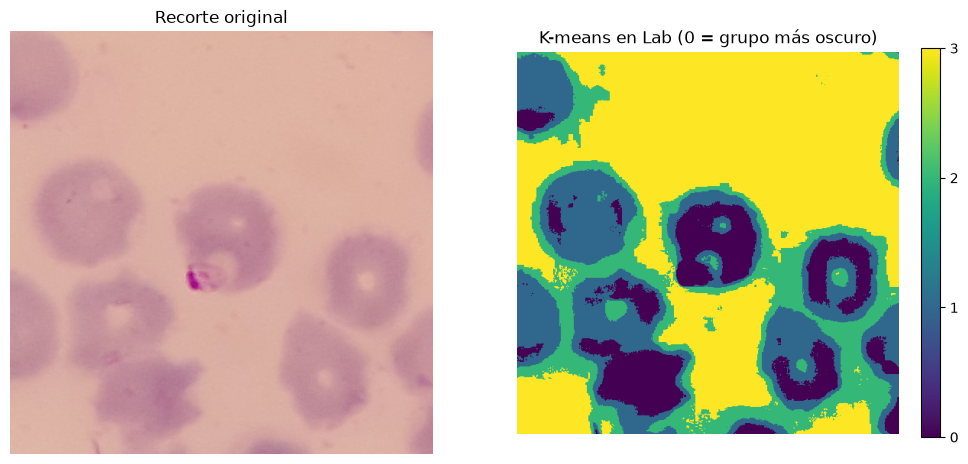

In [47]:
lab_zoom = cv2.cvtColor(zoom, cv2.COLOR_RGB2LAB).reshape(-1, 3).astype(float)
lab_zoom_est = (lab_zoom - lab_zoom.mean(axis=0)) / lab_zoom.std(axis=0)

kmeans_zoom = KMeans(n_clusters=4, random_state=SEED, n_init=10).fit(lab_zoom_est)
grupos_zoom = kmeans_zoom.labels_.reshape(zoom.shape[:2])

# Ordenamos los grupos de más oscuro a más claro (por su L medio) para que los colores sean interpretables
orden = np.argsort([lab_zoom[kmeans_zoom.labels_ == g, 0].mean() for g in range(4)])
grupos_ordenados = np.argsort(orden)[grupos_zoom]

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(zoom)
ax[0].set_title("Recorte original")
im = ax[1].imshow(grupos_ordenados, cmap="viridis")
ax[1].set_title("K-means en Lab (0 = grupo más oscuro)")
fig.colorbar(im, ax=ax[1], ticks=range(4), fraction=0.046)
for a in ax:
    a.axis("off")
plt.show()

## 8. Conclusiones de C1 y qué le pasamos al Bloque A

| Problema | Canal recomendado | Regla exploratoria (train) | Comentario |
|---|---|---|---|
| **Fondo vs células** | **G** (o L, casi igual) | célula si **G < 170** | AUC ≈0.97. Respalda usar Otsu sobre el verde. |
| **Excluir glóbulos blancos** | **b** de Lab | violeta si **b < 127** | AUC ≈0.92. Alternativas: H_rot < 80, a > 155. El núcleo del WBC es muy oscuro (G cerca de 0). |
| **Parasitada vs no parasitada** | **G_p5**, L_p5, b_p5 **por célula** | parasitada si **G_p5 < 134** | Por píxel no alcanza (AUC ≤0.68); por célula AUC ≈0.87. |

(Los valores exactos son los de la tabla de la sección 6.)

**Conclusiones:**
1. **No hay un espacio de color que gane en todo**, depende de la tarea:
   - Para lo **oscuro** (fondo vs células, y parásito por célula), **G** de RGB y **L** de Lab son prácticamente equivalentes, con G apenas mejor (el violeta absorbe el verde).
   - Para lo **violeta** (excluir glóbulos blancos), el mejor es **b** de Lab.
2. **HSV** es el menos práctico: H es circular y hay que rotarlo; V es casi igual a R y separa poco.
3. El parásito se detecta por sus **píxeles más oscuros/violetas**, no por el color medio de la célula → esto motiva C3 (máscara de regiones oscuras/violetas) y C4 (proporción de píxeles oscuros/violetas por célula).
4. La tinción es bastante estable entre imágenes de train; la normalización de C2 queda como mejora para test.
5. Todo se ajustó **solo con train** (`SEED = 42`).